# Baseline checkpoint: cost comparison figure
This notebook creates `baseline.png` from saved, verified nested-CV and paired-bootstrap results. It does not download data, refit models, tune thresholds, or access the sealed test set. Run all cells using the project virtual environment.

The figure compares default thresholds with thresholds chosen only from inner-CV OOF predictions. All intervals are conditional on fitted models, thresholds, folds and observed class counts.

In [1]:
from pathlib import Path
import json
import sys
from IPython.display import Image, display
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root / 'src'))
summary = json.loads((root / 'reports/class_weight/comparison/summary.json').read_text())
assert summary['status'] == 'SUCCESS'
assert summary['sealed_test_accessed'] is False
for metric in ['unweighted_default_mean_cost', 'balanced_default_mean_cost',
               'unweighted_tuned_mean_cost', 'balanced_tuned_mean_cost']:
    result = summary['metrics'][metric]
    print(metric, result['point_estimate'], result['conditional_95_percentile_interval'])

unweighted_default_mean_cost 0.038693148324491 [0.03440325579286265, 0.04302373826690246]
balanced_default_mean_cost 0.032830000453453044 [0.030313109327529137, 0.035532580601278736]
unweighted_tuned_mean_cost 0.015109055457307397 [0.012029769192400126, 0.01828787466557838]
balanced_tuned_mean_cost 0.01518160794449735 [0.012206842606448103, 0.018360313789507095]


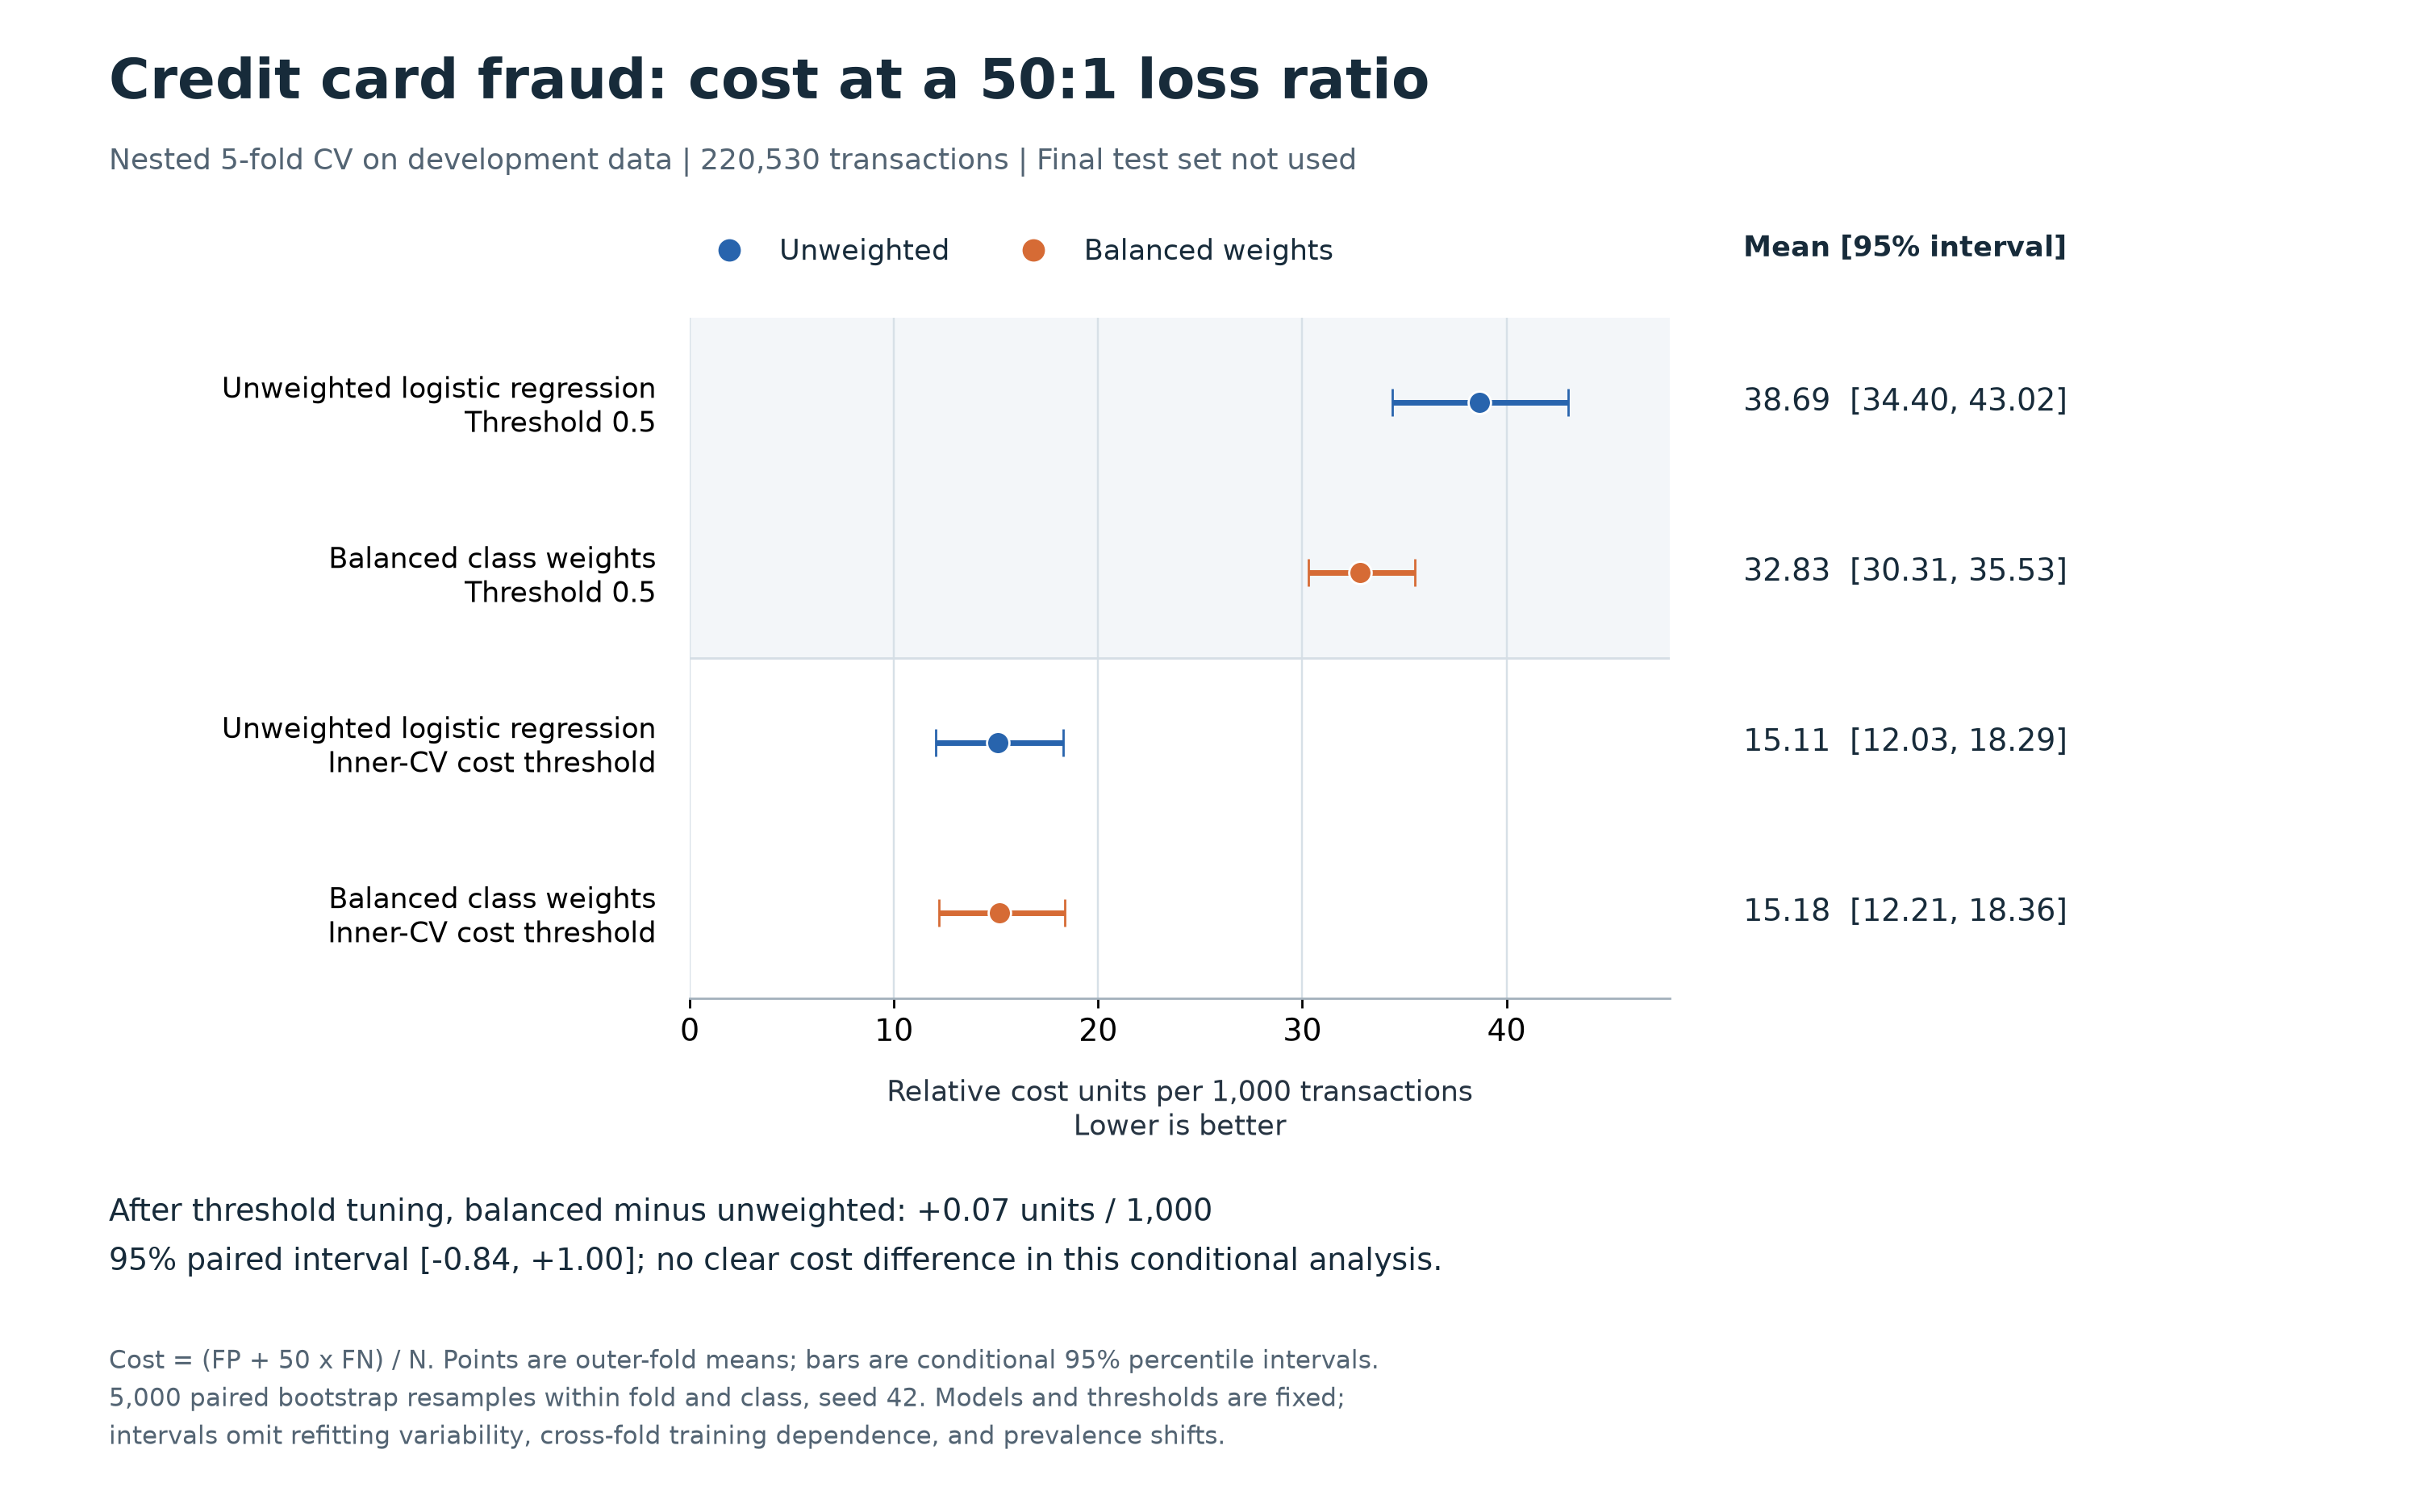

Saved: baseline.png


In [2]:
from plot_baseline import save_figure
import matplotlib.pyplot as plt
figure, path = save_figure(root / 'baseline.png')
plt.close(figure)
display(Image(filename=str(path)))
print('Saved:', path.name)

## Interpretation
At the predeclared 50:1 loss ratio, inner-CV threshold selection reduces observed cost for both models relative to their default 0.5 decisions. After threshold tuning, the paired balanced-minus-unweighted interval includes zero. This is an early checkpoint figure at one cost ratio; a cost-versus-ratio curve requires additional prespecified analysis. Intervals do not represent uncertainty over retraining or future prevalence shifts.